# D+2 forecast of zero-price hours: backtest

At about 13:00 Europe/Madrid on day D, for each clock hour of delivery day D+2: the probability that the OMIE day-ahead price for Spain clears at or below 0 EUR/MWh.

**What the forecast may use** (`spain_power.forecast.available_at`)
- Prices through the end of D+1. The day-ahead result for D+1 is published around 13:00 on D and is treated as known.
- REE generation and demand through the end of D-1 only. The real-time feed for D is half a day short at 13:00, so D is left out.
- Weather forecasts issued 72 hours before each target hour (Open-Meteo Previous Runs API, `_previous_day3` fields). For the last hour of D+2 that is 23:00 on D-1. The 48-hour fields would come from runs started after 13:00 on D for every afternoon hour, so they are not used. Observed or reanalysis weather is never used.
- The calendar of D+2.

**Backtest.** Rolling origin, one forecast per day, expanding training window, weekly retrain, at least 90 training days. The model is scikit-learn's `HistGradientBoostingClassifier` with settings fixed before the run. Baselines: *same as D+1*, *same hour last week*, and a month × hour *climatology* from the training window.

This notebook reads the outputs of `python scripts/backtest_forecast.py` (about 10 minutes); it does not rerun it. Weather forecasts by Open-Meteo.com (CC BY 4.0).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
import plotly.io as pio

from spain_power import case_study, charts, forecast

pio.renderers.default = "png"  # static images so the notebook renders on GitHub
pd.set_option("display.float_format", "{:,.3f}".format)

res = forecast.load_results(ROOT / "docs" / "forecast_results.json")
bt = pd.read_parquet(ROOT / "data" / "processed" / "forecast_backtest.parquet")
m = res["meta"]
COLS = ["precision", "recall", "f1", "brier", "day_exact", "day_exact_zero_days", "day_any"]


def table(block):
    return pd.DataFrame({res["labels"][k]: v for k, v in block.items() if v}).T[COLS].astype(float)


print(f"{m['target_days']} target days, {m['first_target']} to {m['last_target']}; data through {m['data_end']}")
print(f"{m['zero_hours']:,} zero hours of {m['hours']:,} ({m['zero_hours'] / m['hours']:.1%}); {m['retrains']} retrains")
print(f"{sum(len(v) for v in m['features'].values())} features; weather lead: {m['weather_lead']}")

641 target days, 2025-01-06 to 2026-10-08; data through 2026-10-09
1,708 zero hours of 15,383 (11.1%); 92 retrains
41 features; weather lead: previous_day3


## 1. Model vs baselines

The positive class is price ≤ 0. `brier` is the mean squared error of the probability (lower is better); the two price baselines count as probabilities of 0 or 1. `day_exact` is the share of days where the predicted set of zero hours equals the actual set. A day with no zero hours is matched by predicting none, so `day_exact_zero_days` gives the same share over days that had at least one. `day_any` is the share of days where "at least one zero hour" was called correctly.

In [2]:
print(case_study.forecast_verdict(res))
table(res["overall"])

The model beats all three baselines on this backtest: F1 for zero hours is 0.77 against 0.67 for the best baseline ("same as D+1"), and the Brier score is 0.038 against 0.069 (climatology; lower is better).


,precision,recall,f1,brier,day_exact,day_exact_zero_days,day_any
"Model, p ≥ 0.5",0.794,0.744,0.768,0.038,0.602,0.147,0.869
"Model, threshold tuned on training data",0.659,0.835,0.736,0.038,0.555,0.124,0.857
"Model without weather, p ≥ 0.5",0.765,0.684,0.723,0.044,0.588,0.112,0.846
Baseline: same as D+1,0.675,0.674,0.675,0.072,0.529,0.073,0.805
Baseline: same hour last week,0.631,0.630,0.631,0.082,0.515,0.062,0.786
Baseline: climatology (month × hour),0.613,0.404,0.487,0.069,0.524,0.035,0.697


In [3]:
for key, d in {**res["vs_baselines"], "model_no_weather": res["vs_no_weather"]}.items():
    print(f"model minus {key}: F1 {d['f1_diff']:+.3f} (95% {d['f1_ci'][0]:+.3f} to {d['f1_ci'][1]:+.3f}), "
          f"Brier {d['brier_diff']:+.4f} (95% {d['brier_ci'][0]:+.4f} to {d['brier_ci'][1]:+.4f})")
print(f"intervals: {res['vs_baselines']['same_as_d1']['resamples']:,} resamples of whole days")

model minus same_as_d1: F1 +0.093 (95% +0.060 to +0.128), Brier -0.0345 (95% -0.0414 to -0.0274)
model minus last_week: F1 +0.138 (95% +0.105 to +0.174), Brier -0.0443 (95% -0.0513 to -0.0376)
model minus climatology: F1 +0.281 (95% +0.233 to +0.335), Brier -0.0310 (95% -0.0367 to -0.0255)
model minus model_no_weather: F1 +0.046 (95% +0.024 to +0.067), Brier -0.0062 (95% -0.0086 to -0.0039)
intervals: 2,000 resamples of whole days


The stored hourly forecasts reproduce the table: the same metrics, recomputed here from `forecast_backtest.parquet`.

In [4]:
check = pd.DataFrame({res["labels"][k]: forecast.evaluate(bt, pred, prob) for k, (_, pred, prob) in forecast.METHODS.items()}).T[COLS].astype(float)
assert (check - table(res["overall"])).abs().max().max() < 1e-4
print(f"tuned threshold: median {m['tuned_threshold_median']:.2f}, range {m['tuned_threshold_range'][0]:.2f} to {m['tuned_threshold_range'][1]:.2f}")

tuned threshold: median 0.25, range 0.05 to 0.95


## 2. Calibration

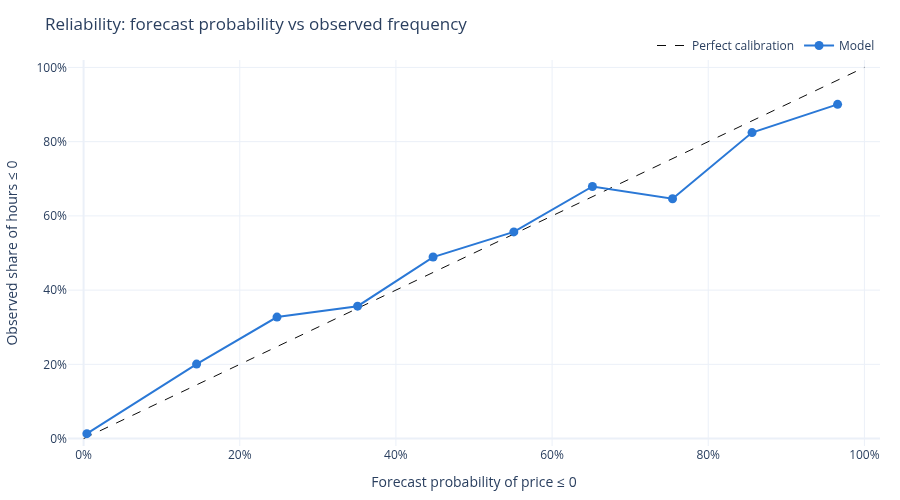

In [5]:
charts.fig_reliability(res["reliability"]).show(width=900, height=500)

In [6]:
pd.DataFrame(res["reliability"]).set_index("bin")

,n,mean_p,observed
bin,,,
0.0–0.1,12929,0.004,0.013
0.1–0.2,319,0.145,0.201
0.2–0.3,226,0.248,0.327
0.3–0.4,171,0.351,0.357
0.4–0.5,137,0.448,0.489
0.5–0.6,167,0.551,0.557
0.6–0.7,159,0.652,0.679
0.7–0.8,212,0.754,0.646
0.8–0.9,319,0.856,0.825


## 3. By season
Season of the target day. Zero hours are a spring, midday event, so the other seasons have few positives and noisier scores.

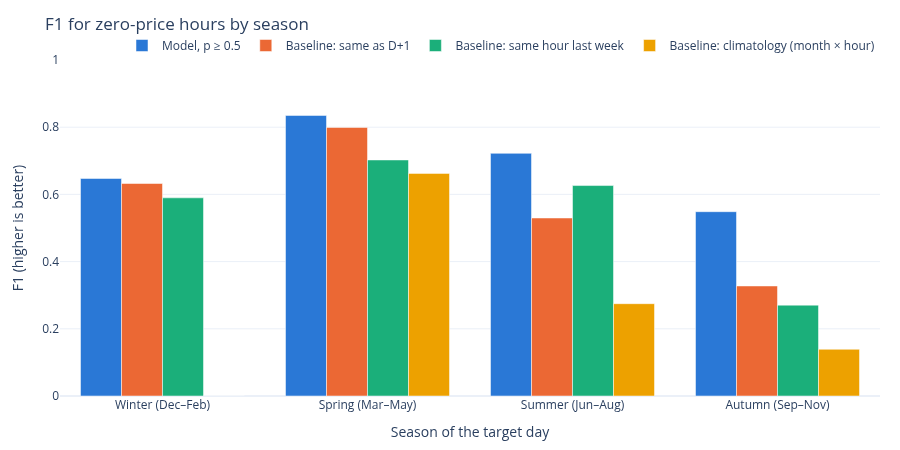

In [7]:
charts.fig_forecast_seasons(res["by_season"], res["labels"], ["model", "same_as_d1", "last_week", "climatology"]).show(width=900, height=450)

In [8]:
pd.concat({s: table(b) for s, b in res["by_season"].items() if b.get("model")})

precision  recall  \
Winter (Dec–Feb) Model, p ≥ 0.5                               0.806   0.541   
                 Model, threshold tuned on training data      0.543   0.696   
                 Model without weather, p ≥ 0.5               0.731   0.498   
                 Baseline: same as D+1                        0.642   0.623   
                 Baseline: same hour last week                0.663   0.531   
                 Baseline: climatology (month × hour)         0.000   0.000   
Spring (Mar–May) Model, p ≥ 0.5                               0.818   0.853   
                 Model, threshold tuned on training data      0.709   0.945   
                 Model without weather, p ≥ 0.5               0.795   0.804   
                 Baseline: same as D+1                        0.804   0.795   
                 Baseline: same hour last week                0.719   0.687   
                 Baseline: climatology (month × hour)         0.720   0.613   
Summer (Jun–Aug) Model, p ≥ 0.5                               0.762   0.686   
                 Model, threshold tuned on training data      0.704   0.735   
                 Model without weather, p ≥ 0.5               0.768   0.606   
                 Baseline: same as D+1                        0.529   0.530   
                 Baseline: same hour last week                0.600   0.654   
                 Baseline: climatology (month × hour)         0.350   0.226   
Autumn (Sep–Nov) Model, p ≥ 0.5                               0.657   0.471   
                 Model, threshold tuned on training data      0.396   0.580   
                 Model without weather, p ≥ 0.5               0.515   0.377   
                 Baseline: same as D+1                        0.315   0.341   
                 Baseline: same hour last week                0.239   0.312   
                 Baseline: climatology (month × hour)         0.265   0.094   

                                                            f1  brier  \
Winter (Dec–Feb) Model, p ≥ 0.5                          0.647  0.027   
                 Model, threshold tuned on training data 0.610  0.027   
                 Model without weather, p ≥ 0.5          0.592  0.029   
                 Baseline: same as D+1                   0.632  0.043   
                 Baseline: same hour last week           0.590  0.044   
                 Baseline: climatology (month × hour)    0.000  0.050   
Spring (Mar–May) Model, p ≥ 0.5                          0.835  0.054   
                 Model, threshold tuned on training data 0.810  0.054   
                 Model without weather, p ≥ 0.5          0.799  0.065   
                 Baseline: same as D+1                   0.799  0.086   
                 Baseline: same hour last week           0.703  0.126   
                 Baseline: climatology (month × hour)    0.662  0.096   
Summer (Jun–Aug) Model, p ≥ 0.5                          0.722  0.036   
                 Model, threshold tuned on training data 0.719  0.036   
                 Model without weather, p ≥ 0.5          0.678  0.040   
                 Baseline: same as D+1                   0.530  0.088   
                 Baseline: same hour last week           0.626  0.073   
                 Baseline: climatology (month × hour)    0.275  0.077   
Autumn (Sep–Nov) Model, p ≥ 0.5                          0.548  0.028   
                 Model, threshold tuned on training data 0.471  0.028   
                 Model without weather, p ≥ 0.5          0.435  0.034   
                 Baseline: same as D+1                   0.328  0.062   
                 Baseline: same hour last week           0.270  0.075   
                 Baseline: climatology (month × hour)    0.139  0.039   

                                                          day_exact  \
Winter (Dec–Feb) Model, p ≥ 0.5                               0.812   
                 Model, threshold tuned on training data      0.806   
                 Model without weather, p ≥

## 4. Where it fails

- **Onset day:** at least one zero hour after seven days without any. Both price baselines miss these by construction.
- **Streak break:** D+1 had zero hours (so *same as D+1* predicts some) but D+2 has none.
- **Hour groups:** zero hours outside midday are few and mostly wind-driven.

In [9]:
f = res["failures"]
o, b = f["onset"], f["streak_break"]
print(f"Onset days: {o['days']} ({o['zero_hours']} zero hours). Model flagged {o['model_days_flagged']} days, hour recall {o['model_recall']:.0%}.")
print(f"Streak breaks: {b['days']} days. False hours: model {b['model_false_hours']} (on {b['model_days_flagged']} days), same as D+1 {b['d1_false_hours']}.")
pd.DataFrame(f["hour_groups"]).T

Onset days: 12 (44 zero hours). Model flagged 1 days, hour recall 11%.
Streak breaks: 62 days. False hours: model 82 (on 19 days), same as D+1 345.


,zero_hours,model_precision,model_recall,d1_recall,week_recall
Night (20:00–07:59),67.000,0.538,0.313,0.507,0.403
"Shoulder (08:00–09:59, 18:00–19:59)",95.000,0.602,0.558,0.390,0.390
Midday (10:00–17:59),"1,546.000",0.812,0.774,0.699,0.655


Three days picked by rule: the onset day with the most missed hours, the streak break with the most hours wrongly called, and the day with the most missed night hours. The `forecast_*` values are what the model saw (72-hour-ahead daily means, with the day before in `*_prev`); the `*_share` values are what then happened (share of demand).

In [10]:
pd.DataFrame(f["examples"]).set_index("date").T

date,2026-03-12,2025-04-21,2026-01-31
kind,onset,streak_break,night
origin,2026-03-10,2025-04-19,2026-01-29
actual_hours,"[11, 12, 13, 14, 15, 16]",[],"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14..."
model_hours,[],"[11, 12, 13, 14, 15, 16, 17, 18]",[]
d1_hours,[],"[10, 11, 12, 13, 14, 15, 16, 17, 18]",[]
week_hours,[],"[14, 15, 16, 17]",[]
max_p,0.012,0.977,0.294
min_price,-0.010,6.560,-0.440
forecast_rad,224.667,194.115,102.771
forecast_rad_prev,177.552,214.552,78.771


In [11]:
for e in f["examples"]:
    day = bt[bt["date"] == e["date"]].set_index("hour")
    print(e["date"], e["kind"])
    print(day.loc[day["y"] | day["pred_model"] | day["base_d1"], ["price", "p_model", "pred_model", "base_d1", "base_week"]].round(3).to_string(), "\n")

2026-03-12 onset
      price  p_model  pred_model  base_d1  base_week
hour                                                
11   -0.005    0.004       False    False      False
12   -0.005    0.012       False    False      False
13   -0.010    0.007       False    False      False
14   -0.008    0.002       False    False      False
15   -0.008    0.002       False    False      False
16   -0.002    0.001       False    False      False 

2025-04-21 streak_break
      price  p_model  pred_model  base_d1  base_week
hour                                                
10   25.740    0.105       False     True      False
11   15.000    0.690        True     True      False
12   11.830    0.777        True     True      False
13    8.120    0.977        True     True      False
14    6.560    0.974        True     True       True
15    9.270    0.952        True     True       True
16   11.940    0.779        True     True       True
17   20.330    0.773        True     True       True
18 

## 5. Limits

- **One path.** A single rolling backtest; the intervals above cover day-to-day sampling only, not model or period choice.
- **Revised inputs.** The REE figures are today's values, scaled to official daily totals that REE revises for weeks. A live forecast would see earlier versions.
- **Hourly target.** Since 1 Oct 2025 the market clears in 15-minute periods and the target is the hourly mean, so a quarter-hour at or below zero inside a positive hour is not counted.
- **Weather timing.** The 72-hour lead rests on Open-Meteo's description of its archived forecasts; the archive mixes weather models and may not match what a user saw live.
- **No live run yet.** These are backtest results, not a record of forecasts made in real time.